In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt 

In [2]:
baseball = pd.read_csv("cleaned_batting_stats.csv")
cleaned_baseball = baseball.copy()

In [3]:
cleaned_baseball.head(5)

,Rk,Player,Age,Team,Lg,WAR,G,PA,AB,R,...,TB,GIDP,HBP,SH,SF,IBB,Pos,Awards,Year,RowNum
0,357.0,A.J. Ellis,35.0,2TM,NL,-0.1,64.0,196.0,171.0,11.0,...,51.0,5.0,2.0,3.0,1.0,2.0,2/H,NaN,2016,1
1,416.0,AJ Pollock,35.0,2TM,2LG,-0.7,54.0,144.0,133.0,15.0,...,41.0,1.0,0.0,0.0,2.0,0.0,7DH/89,NaN,2023,1
2,284.0,Aaron Hicks#,33.0,2TM,AL,0.5,93.0,312.0,269.0,44.0,...,103.0,3.0,0.0,0.0,1.0,1.0,879H/D,NaN,2023,1
3,193.0,Aaron Hill,34.0,2TM,2LG,1.5,125.0,429.0,378.0,48.0,...,143.0,6.0,3.0,0.0,4.0,2.0,54H/D,NaN,2016,1
4,301.0,Abraham Almonte#,26.0,2TM,2LG,0.8,82.0,258.0,232.0,36.0,...,95.0,5.0,0.0,3.0,2.0,0.0,8H/79D,NaN,2015,1


In [4]:
cleaned_baseball.columns

Index(['Rk', 'Player', 'Age', 'Team', 'Lg', 'WAR', 'G', 'PA', 'AB', 'R', 'H',
       '2B', '3B', 'HR', 'RBI', 'SB', 'CS', 'BB', 'SO', 'BA', 'OBP', 'SLG',
       'OPS', 'OPS+', 'rOBA', 'Rbat+', 'TB', 'GIDP', 'HBP', 'SH', 'SF', 'IBB',
       'Pos', 'Awards', 'Year', 'RowNum'],
      dtype='object')

In [5]:
cleaned_baseball.dtypes

Rk        float64
Player     object
Age       float64
Team       object
Lg         object
WAR       float64
G         float64
PA        float64
AB        float64
R         float64
H         float64
2B        float64
3B        float64
HR        float64
RBI       float64
SB        float64
CS        float64
BB        float64
SO        float64
BA        float64
OBP       float64
SLG       float64
OPS       float64
OPS+      float64
rOBA      float64
Rbat+     float64
TB        float64
GIDP      float64
HBP       float64
SH        float64
SF        float64
IBB       float64
Pos        object
Awards     object
Year        int64
RowNum      int64
dtype: object

**data cleaning**
<br>drop columns of Rk and RowNum</br>

In [6]:
cleaned_baseball = cleaned_baseball.drop(columns=["Rk", "RowNum", "Pos"])
cleaned_baseball

,Player,Age,Team,Lg,WAR,G,PA,AB,R,H,...,rOBA,Rbat+,TB,GIDP,HBP,SH,SF,IBB,Awards,Year
0,A.J. Ellis,35.0,2TM,NL,-0.1,64.0,196.0,171.0,11.0,37.0,...,0.279,62.0,51.0,5.0,2.0,3.0,1.0,2.0,NaN,2016
1,AJ Pollock,35.0,2TM,2LG,-0.7,54.0,144.0,133.0,15.0,22.0,...,0.233,48.0,41.0,1.0,0.0,0.0,2.0,0.0,NaN,2023
2,Aaron Hicks#,33.0,2TM,AL,0.5,93.0,312.0,269.0,44.0,68.0,...,0.328,106.0,103.0,3.0,0.0,0.0,1.0,1.0,NaN,2023
3,Aaron Hill,34.0,2TM,2LG,1.5,125.0,429.0,378.0,48.0,99.0,...,0.321,88.0,143.0,6.0,3.0,0.0,4.0,2.0,NaN,2016
4,Abraham Almonte#,26.0,2TM,2LG,0.8,82.0,258.0,232.0,36.0,58.0,...,0.317,86.0,95.0,5.0,0.0,3.0,2.0,0.0,NaN,2015
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4497,Yadiel HernÃ¡ndez*,34.0,WSN,NL,0.6,94.0,327.0,305.0,30.0,82.0,...,0.323,109.0,125.0,9.0,1.0,0.0,2.0,0.0,NaN,2022
4498,Yan Gomes,32.0,WSN,NL,0.7,30.0,119.0,109.0,14.0,31.0,...,0.351,115.0,51.0,1.0,1.0,0.0,3.0,0.0,NaN,2020
4499,Yan Gomes,31.0,WSN,NL,1.4,97.0,358.0,314.0,36.0,70.0,...,0.311,79.0,122.0,7.0,5.0,0.0,1.0,6.0,NaN,2019
4500,Yan Gomes,33.0,WSN,NL,2.0,63.0,235.0,218.0,30.0,59.0,...,0.337,111.0,99.0,12.0,4.0,0.0,0.0,3.0,NaN,2021


**Check Data Types for Numeric Columns**

Age       float64
WAR       float64
G         float64
PA        float64
AB        float64
R         float64
H         float64
2B        float64
3B        float64
HR        float64
RBI       float64
SB        float64
CS        float64
BB        float64
SO        float64
OPS+      float64
TB        float64
GIDP      float64
HBP       float64
SH        float64
SF        float64
IBB       float64

In [7]:
numerics = ["Age", "G", "PA", "AB", "R", "H", "2B", "3B", "HR", "RBI", "SB", "CS", "BB", "SO", "OPS+", "TB", "GIDP", "HBP", "SH", "SF", "IBB", "Rbat+"]

In [8]:
cleaned_baseball[numerics] = cleaned_baseball[numerics].astype("int64")
cleaned_baseball.head(5)

,Player,Age,Team,Lg,WAR,G,PA,AB,R,H,...,rOBA,Rbat+,TB,GIDP,HBP,SH,SF,IBB,Awards,Year
0,A.J. Ellis,35,2TM,NL,-0.1,64,196,171,11,37,...,0.279,62,51,5,2,3,1,2,NaN,2016
1,AJ Pollock,35,2TM,2LG,-0.7,54,144,133,15,22,...,0.233,48,41,1,0,0,2,0,NaN,2023
2,Aaron Hicks#,33,2TM,AL,0.5,93,312,269,44,68,...,0.328,106,103,3,0,0,1,1,NaN,2023
3,Aaron Hill,34,2TM,2LG,1.5,125,429,378,48,99,...,0.321,88,143,6,3,0,4,2,NaN,2016
4,Abraham Almonte#,26,2TM,2LG,0.8,82,258,232,36,58,...,0.317,86,95,5,0,3,2,0,NaN,2015


**Create booleans for awards**

**Remove Weird Asterisks and Funky Naming Conventions**
<br>-remove # </br>
<br>-remove accents </br> 
<br>-remove weird encoding </br>
<br>-remove *
<br>-remove whitespace </br>

In [9]:
import unicodedata

def fix_mojibake(s):
    if not isinstance(s, str):
        return s
    try:
        return s.encode("latin-1").decode("utf-8")
    except (UnicodeEncodeError, UnicodeDecodeError):
        return s

def strip_accents(s):
    if not isinstance(s, str):
        return s
    return ''.join(
        c for c in unicodedata.normalize('NFKD', s)
        if not unicodedata.combining(c)
    )

cleaned_baseball["Player"] = (
    cleaned_baseball["Player"]
        .apply(fix_mojibake)
        .apply(strip_accents)
        .str.replace(r"[#*]", "", regex=True)
        .str.strip()
)

In [10]:
# Step 4: Remove duplicate team rows FIRST ← key fix
def remove_duplicate_team_rows(df):
    multi_team = df[df["Team"].str.contains("TM", na=False)][["Player", "Year"]]
    multi_team["is_multi"] = True
    df = df.merge(multi_team, on=["Player", "Year"], how="left")
    df = df[~((df["is_multi"] == True) & (~df["Team"].str.contains("TM", na=False)))]
    df = df.drop(columns=["is_multi"])
    return df

cleaned_baseball = remove_duplicate_team_rows(cleaned_baseball)

In [28]:
cleaned_baseball["Rookie Of The Year"] = np.where(cleaned_baseball["Awards"].str.contains(r"ROY-1(?!\d)", na=False, regex=True), 1, 0).astype(bool)
cleaned_baseball["All Star Appearance"] = np.where(cleaned_baseball["Awards"].str.contains("AS", na=False), 1, 0).astype(bool)
cleaned_baseball["MVP"] = np.where(cleaned_baseball["Awards"].str.contains(r"MVP-1(?!\d)", na=False, regex=True), 1, 0).astype(bool)
cleaned_baseball["Sliver Slugger"] = np.where(cleaned_baseball["Awards"].str.contains("SS", na=False), 1, 0).astype(bool)
cleaned_baseball["Considered for Rookie Of The Year"] = np.where(cleaned_baseball["Awards"].str.contains("ROY", na=False), 1, 0).astype(bool)
cleaned_baseball["Considered for MVP"] = np.where(cleaned_baseball["Awards"].str.contains(r"MVP(?!\d)", na=False, regex=True), 1, 0).astype(bool)

**Create Boolean for Players who played for more than one team**

In [29]:
multiple = ["2TM", "3TM", "4TM"]
cleaned_baseball["Played For Multiple Teams"] = np.where(cleaned_baseball["Team"].isin(multiple), 1, 0).astype(bool)

In [30]:
cleaned_baseball.dtypes

Player                                object
Age                                    int64
Team                                  object
Lg                                    object
WAR                                  float64
G                                      int64
PA                                     int64
AB                                     int64
R                                      int64
H                                      int64
2B                                     int64
3B                                     int64
HR                                     int64
RBI                                    int64
SB                                     int64
CS                                     int64
BB                                     int64
SO                                     int64
BA                                   float64
OBP                                  float64
SLG                                  float64
OPS                                  float64
OPS+      

**Which team employed the most amount of position players**
- records with 2TM, 3TM and 4TM are removed for this analysis
- smaller markets like tampa bay, minnesota and cleveland are towards the top as they don't have the funds to keep players when their contracts are up

In [31]:
players_without_multiple = cleaned_baseball[~cleaned_baseball["Team"].isin(multiple)]

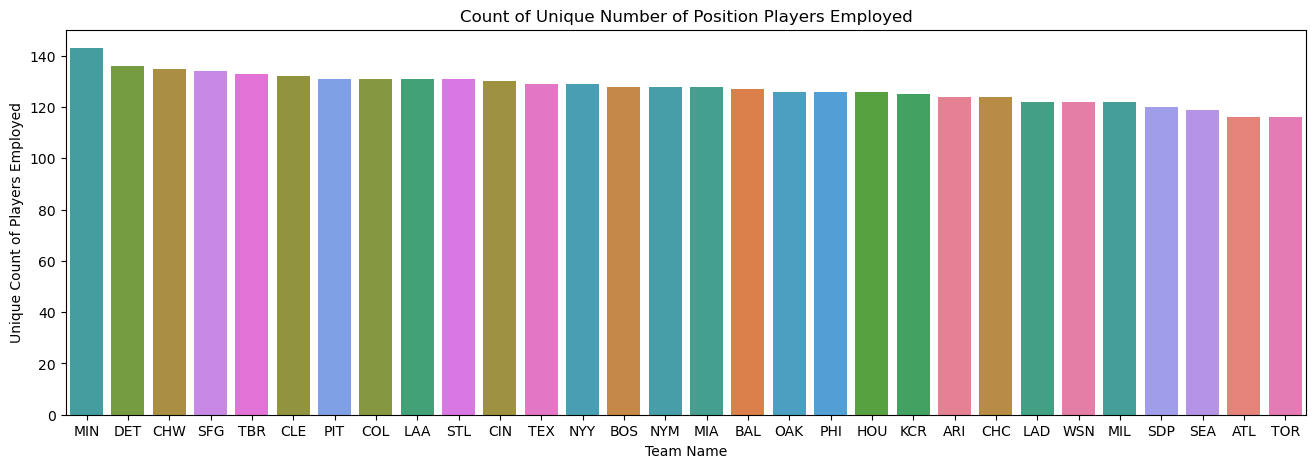

In [32]:
order = players_without_multiple["Team"].value_counts().index
plt.figure(figsize=(16, 5))
sns.countplot(data=players_without_multiple, x="Team", order=order, hue="Team")
plt.title("Count of Unique Number of Position Players Employed")
plt.xlabel("Team Name")
plt.ylabel("Unique Count of Players Employed")
plt.show()

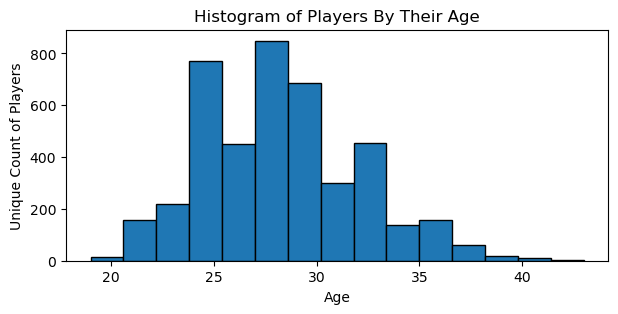

In [33]:
order1 = cleaned_baseball["Age"].value_counts().index
plt.figure(figsize=(7, 3))
plt.title("Histogram of Players By Their Age")
plt.hist(data=cleaned_baseball, x="Age", bins=15, edgecolor="black")
plt.xlabel("Age")
plt.ylabel("Unique Count of Players")
plt.show()

In [34]:
homers = pd.pivot_table(cleaned_baseball, index="Player", values="HR", aggfunc="sum")
top_1o_pivot = homers.nlargest(10, "HR")
print(top_1o_pivot)

                    HR
Player                
Nolan Arenado      313
Aaron Judge        311
Manny Machado      309
J.D. Martinez      284
Kyle Schwarber     284
Bryce Harper       281
Mike Trout         280
Paul Goldschmidt   279
Eugenio Suarez     272
Giancarlo Stanton  268


In [35]:
strikeouts = pd.pivot_table(cleaned_baseball, index="Player", values="SO", aggfunc="sum")
most_strikeout_prone = strikeouts.nlargest(10, "SO")
print(most_strikeout_prone)

                    SO
Player                
Eugenio Suarez    1551
Paul Goldschmidt  1441
J.D. Martinez     1362
Nick Castellanos  1343
Kyle Schwarber    1328
Tommy Pham        1312
Joey Gallo        1273
Paul DeJong       1232
Bryce Harper      1215
Christian Yelich  1178


In [36]:
allstar = cleaned_baseball[cleaned_baseball["All Star Appearance"] == True]

allstarappearance = pd.pivot_table(allstar, index="Player", values="All Star Appearance", aggfunc="sum")
most_all_stars = allstarappearance.nlargest(10, "All Star Appearance")
print(most_all_stars)

                 All Star Appearance
Player                              
Mike Trout                         8
Mookie Betts                       8
Nolan Arenado                      8
Jose Altuve                        7
Salvador Perez                     7
Aaron Judge                        6
Bryce Harper                       6
Freddie Freeman                    6
J.D. Martinez                      6
Jose Ramirez                       6


In [37]:
MVP = cleaned_baseball[cleaned_baseball["MVP"] == True]

MVPWins = pd.pivot_table(MVP, index="Player", values="MVP", aggfunc="sum")
most_mvps = MVPWins.nlargest(10, "MVP")
print(most_mvps)

                   MVP
Player                
Shohei Ohtani        3
Aaron Judge          2
Bryce Harper         2
Mike Trout           2
Christian Yelich     1
Cody Bellinger       1
Freddie Freeman      1
Giancarlo Stanton    1
Jose Abreu           1
Jose Altuve          1


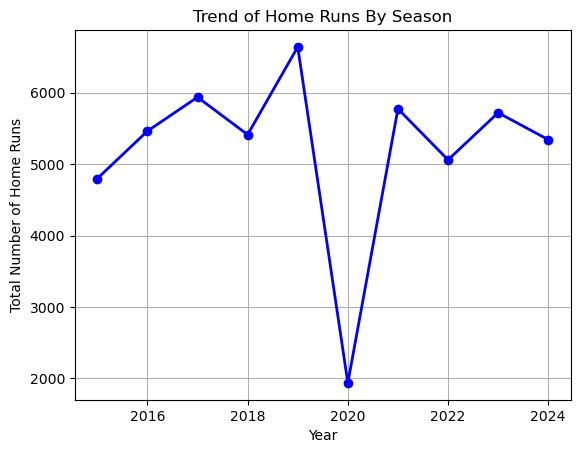

In [39]:
home_runs_totals = cleaned_baseball.groupby("Year")["HR"].sum()

home_runs_totals.plot(kind="line", marker="o", color="blue", linewidth=2)
plt.title("Trend of Home Runs By Season")
plt.xlabel("Year")
plt.ylabel("Total Number of Home Runs")
plt.grid(True)
plt.show()

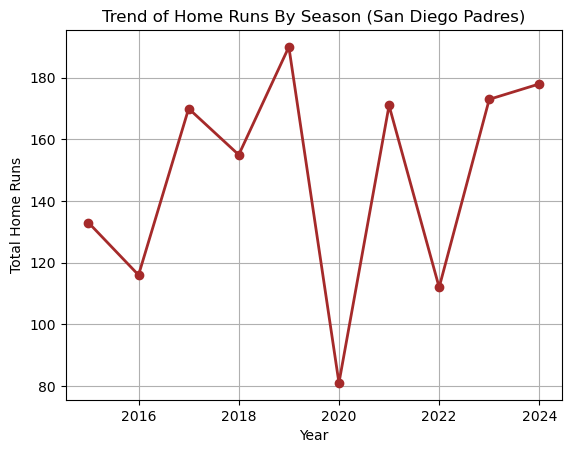

In [40]:
sandiegopadres = cleaned_baseball[cleaned_baseball["Team"] == "SDP"]
padres_homers = sandiegopadres.groupby("Year")["HR"].sum()

padres_homers.plot(kind="line", marker="o", color="brown", linewidth=2)
plt.title("Trend of Home Runs By Season (San Diego Padres)")
plt.xlabel("Year")
plt.ylabel("Total Home Runs")
plt.grid(True)
plt.show()

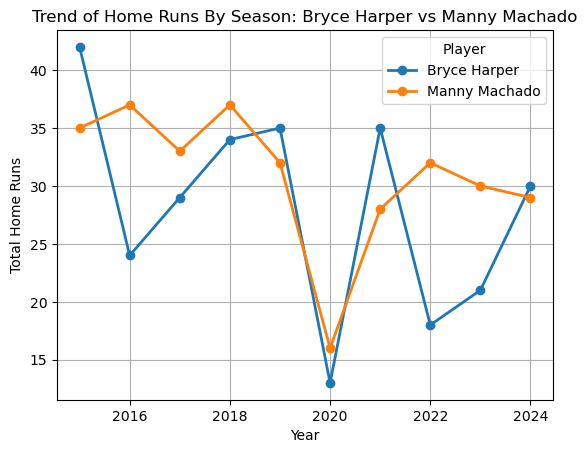

In [42]:
mannyandbryce = cleaned_baseball[cleaned_baseball["Player"].isin(["Manny Machado", "Bryce Harper"])]

home_runs = mannyandbryce.groupby(["Player", "Year"])["HR"].sum().unstack("Player")

home_runs.plot(kind="line", marker="o", linewidth=2)
plt.title("Trend of Home Runs By Season: Bryce Harper vs Manny Machado")
plt.xlabel("Year")
plt.ylabel("Total Home Runs")
plt.legend(title="Player")
plt.grid(True)
plt.show()